In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np
from arch import arch_model
import warnings
from arch.utility.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


daily_df = pd.read_csv('../../data/simulated_daily_data.csv')
daily_df['Date'] = pd.to_datetime(daily_df['Date'])
daily_df = daily_df.set_index('Date').drop(columns='Unnamed: 7')
daily_df['log_return'] = np.log(daily_df['Adj Close']).diff()
five_min_df = pd.read_csv('../../data/simulated_5min_data.csv')
five_min_df['datetime'] = pd.to_datetime(five_min_df['datetime'])
five_min_df['date'] = five_min_df['datetime'].dt.date
five_min_df = five_min_df.set_index('datetime').drop(columns='Unnamed: 6')
five_min_df

,open,low,high,close,volume,date
datetime,,,,,,
2021-09-29 20:00:00,10379.7775,10364.5950,10398.7025,10370.9575,46,2021-09-29
2021-09-29 20:05:00,10370.9425,10352.4175,10380.2500,10371.1450,53,2021-09-29
2021-09-29 20:10:00,10372.8150,10357.8250,10388.7500,10384.3125,116,2021-09-29
2021-09-29 20:15:00,10385.8275,10384.0825,10457.2000,10442.5175,266,2021-09-29
2021-09-29 20:20:00,10442.5225,10426.2375,10448.0000,10440.9950,65,2021-09-29
...,...,...,...,...,...,...
2023-09-20 10:40:00,6792.1025,6783.6000,6796.2500,6790.1375,41,2023-09-20
2023-09-20 10:45:00,6790.5575,6779.1000,6795.7500,6781.9175,42,2023-09-20
2023-09-20 10:50:00,6781.5475,6779.3750,6790.2500,6783.9050,44,2023-09-20


In [10]:
# Calculate 6-month rolling variance, fit GARCH model in 6-month rolling window, and predict next day variance.
# Best GARCH model (by tutorial) for this data is an autoregressive order/lag (p) of 1, and a moving average order/lag (q) of 3.
# In this case, 1 lag = 1 day in the past from the current time period.

daily_df['variance'] = daily_df['log_return'].rolling(180).var() 

def predict_volatility(x): # x is expected to be a time series of returns
    best_model = (arch_model(y=x, p=1, q=3) 
                  .fit(disp='off')) # turns off convergence text
    variance_forecast = (best_model.forecast(horizon=1)
                         .variance # selects the variance dataframe from the forecast object
                         .iloc[-1, 0]) # selects the most recent (last row) variance forecast 
    return variance_forecast

daily_df['predictions'] = daily_df['log_return'].rolling(180).apply(lambda x: predict_volatility(x))


c:\Users\bedel\Downloads\Algorithmic Trading Strategies\venv\Lib\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.001921. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
c:\Users\bedel\Downloads\Algorithmic Trading Strategies\venv\Lib\site-packages\arch\univariate\base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.001894. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
c:\Users

Text(0, 0.5, 'Prediction Premium')

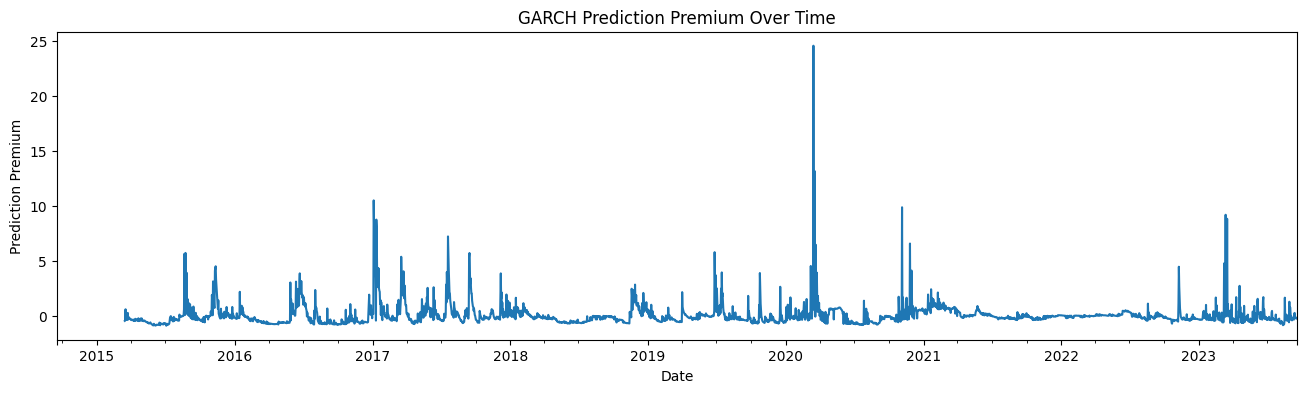

In [11]:
# Calculate prediction premium (market's expectations of future volatility)
daily_df['prediction_premium'] = (daily_df['predictions']-daily_df['variance'])/daily_df['variance']
daily_df['premium_std'] = daily_df['prediction_premium'].rolling(180).std()
daily_df['prediction_premium'].plot(figsize=(16, 4))
plt.title('GARCH Prediction Premium Over Time')
plt.ylabel('Prediction Premium')


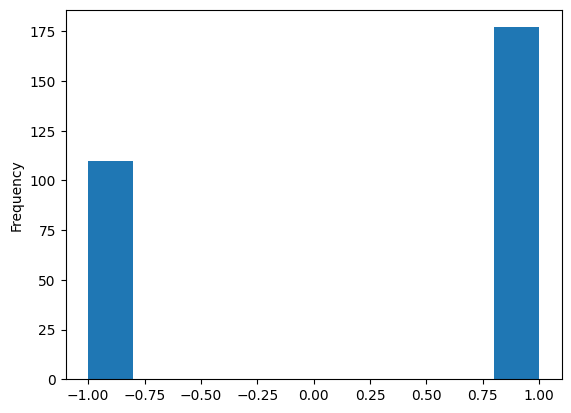

In [12]:
# Daily entry signal is produced when prediction premium > premium standard deviation * 1.5, or < premium std *-1.5
daily_df['signal_daily'] = daily_df.apply(lambda x: 1 if (x['prediction_premium'] > x['premium_std']*1.5)
                                          else (-1 if (x['prediction_premium'] < x['premium_std']*-1.5) else np.nan), axis=1)
daily_df['signal_daily'] = daily_df['signal_daily'].shift()
daily_df['signal_daily'].plot(kind='hist')           
plt.show()


## Backtest: Strategy Returns

Forward-fill signals to maintain position until a new signal is generated.
Strategy return = position direction * next day's log return.

In [13]:
# Forward-fill signals (hold position until new signal)
daily_df['position'] = daily_df['signal_daily'].ffill().fillna(0)

# Strategy return = position * log return
daily_df['strategy_return'] = daily_df['position'] * daily_df['log_return']
daily_df['buy_hold_return'] = daily_df['log_return']

# Drop NaN rows from rolling window warmup
backtest_df = daily_df.dropna(subset=['strategy_return', 'buy_hold_return']).copy()
print(f'Backtest period: {backtest_df.index[0].strftime("%Y-%m-%d")} to {backtest_df.index[-1].strftime("%Y-%m-%d")}')
print(f'Trading days: {len(backtest_df)}')
print(f'Long signals: {(backtest_df["position"] == 1).sum()}')
print(f'Short signals: {(backtest_df["position"] == -1).sum()}')
print(f'Flat (no position): {(backtest_df["position"] == 0).sum()}')

Backtest period: 2014-09-18 to 2023-09-18
Trading days: 3288
Long signals: 2440
Short signals: 437
Flat (no position): 411


In [14]:
def calc_metrics(returns, name):
    total_return = np.exp(returns.sum()) - 1
    ann_return = np.exp(returns.mean() * 252) - 1
    ann_vol = returns.std() * np.sqrt(252)
    sharpe = ann_return / ann_vol if ann_vol > 0 else 0
    cumulative = np.exp(returns.cumsum())
    max_drawdown = (cumulative / cumulative.cummax() - 1).min()
    win_rate = (returns > 0).sum() / (returns != 0).sum()
    return {
        'Strategy': name,
        'Total Return': f'{total_return:.1%}',
        'Annualized Return': f'{ann_return:.1%}',
        'Annualized Volatility': f'{ann_vol:.1%}',
        'Sharpe Ratio': f'{sharpe:.2f}',
        'Max Drawdown': f'{max_drawdown:.1%}',
        'Win Rate': f'{win_rate:.1%}'
    }

metrics = pd.DataFrame([
    calc_metrics(backtest_df['strategy_return'], 'GARCH Strategy'),
    calc_metrics(backtest_df['buy_hold_return'], 'Buy & Hold')
])
metrics.set_index('Strategy')

,Total Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Max Drawdown,Win Rate
Strategy,,,,,,
GARCH Strategy,79442.3%,66.8%,56.3%,1.19,-66.0%,53.2%
Buy & Hold,5750.1%,36.6%,59.8%,0.61,-83.4%,52.9%


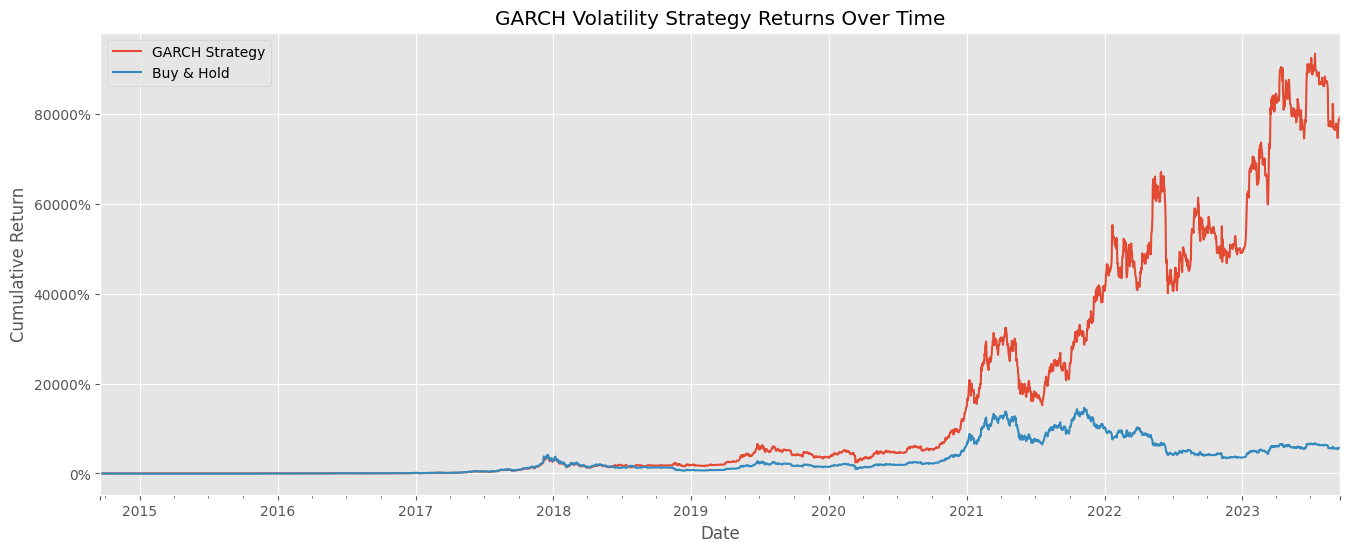

In [15]:
plt.style.use('ggplot')
cumulative = pd.DataFrame({
    'GARCH Strategy': np.exp(backtest_df['strategy_return'].cumsum()) - 1,
    'Buy & Hold': np.exp(backtest_df['buy_hold_return'].cumsum()) - 1
})
cumulative.plot(figsize=(16, 6))
plt.title('GARCH Volatility Strategy Returns Over Time')
plt.ylabel('Cumulative Return')
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.savefig('../../results/garch_volatility_returns.png', dpi=150, bbox_inches='tight')
plt.show()